In [1]:
import tensorflow as tf

I0000 00:00:1794983403.530419   40648 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794983403.539523   40648 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794983404.196047   40648 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794983409.095235   40648 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

In [16]:

import numpy as np


from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report


In [3]:
# Load dataset, features and target
wine = load_wine()

X = wine.data
y = wine.target

print("Features:", X.shape)
print("Labels:", y.shape)


Features: (178, 13)
Labels: (178,)


In [4]:
# split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(142, 13)
(36, 13)
(142,)
(36,)


In [5]:
# standardization
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# neural network
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(13,)),

    tf.keras.layers.Dense(16, activation='relu'),

    tf.keras.layers.Dense(8, activation='relu'),

    tf.keras.layers.Dense(3, activation='softmax')
])

# model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()


E0000 00:00:1794983421.694859   40648 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 387 (1.51 KB)

 Trainable params: 387 (1.51 KB)

 Non-trainable params: 0 (0.00 B)

<bound method Model.summary of <Sequential name=sequential, built=True>>

In [6]:
# Training

history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=16,
    validation_split=0.1,
    verbose=1
)


Epoch 1/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - accuracy: 0.3858 - loss: 1.2898 - val_accuracy: 0.4667 - val_loss: 1.2997
Epoch 2/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.4331 - loss: 1.2002 - val_accuracy: 0.4667 - val_loss: 1.2434
Epoch 3/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.4803 - loss: 1.1273 - val_accuracy: 0.5333 - val_loss: 1.1907
Epoch 4/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.5039 - loss: 1.0608 - val_accuracy: 0.5333 - val_loss: 1.1408
Epoch 5/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.5433 - loss: 1.0024 - val_accuracy: 0.5333 - val_loss: 1.0988
Epoch 6/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5512 - loss: 0.9487 - val_accuracy: 0.5333 - val_loss: 1.0546
Epoch 7/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.5748 - loss: 0.9009 - val_accuracy: 0.5333 - val_loss: 1.0098
Epoch 8/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.5984 - loss: 0.8551 - val_accuracy: 0.6000 - val_loss: 0.9673


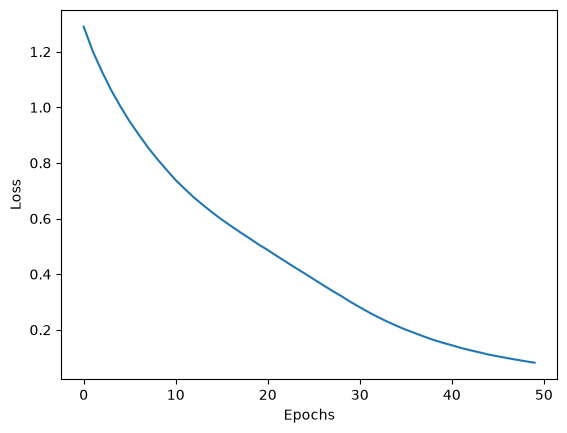

In [13]:
import matplotlib.pyplot as plt

plt.plot(history.epoch, history.history['loss'])
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.show()

In [18]:
# Evaluate 
loss, accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

# Predictions on test data
y_pred_prob = model.predict(X_test)
y_pred = np.argmax(y_pred_prob, axis=1)

print("Predicted: ", y_pred)
print("Actual:    ", y_test)

print("")
accuracy_sklearn = accuracy_score(y_test, y_pred)
print("Accuracy Score: ", accuracy_sklearn)
print("")

print("Classification Report:")
print(classification_report(y_test, y_pred))

# Predict a new sample
new_sample = np.array([1.41119819, -0.16402402, -0.24252429, -0.48245458,  0.36051624,  1.09205418, 1.40697489, -1.17972837,  1.34974202,  0.32679269,  1.33282168,  0.82041452, 2.5646805]).reshape(1, -1)
# new_sample = X_test[0].reshape(1, -1)


prediction = model.predict(new_sample)

predicted_class = np.argmax(prediction, axis=1)[0]

print("\nPredicted Wine Category:", predicted_class)
print("Wine Type:", wine.target_names[predicted_class])



2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.9444 - loss: 0.1307
Test Loss: 0.13074609637260437
Test Accuracy: 0.9444444179534912
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
Predicted:  [0 2 0 1 1 0 0 0 1 2 1 2 0 2 0 1 1 0 1 0 1 1 0 0 0 1 0 2 1 2 0 2 1 2 2 2]
Actual:     [0 2 0 1 1 0 0 1 1 2 1 2 0 2 0 1 1 0 1 0 1 1 0 0 1 1 0 2 1 2 0 2 1 2 2 2]

Accuracy Score:  0.9444444444444444

Classification Report:
              precision    recall  f1-score   support

           0       0.86      1.00      0.92        12
           1       1.00      0.86      0.92        14
           2       1.00      1.00      1.00        10

    accuracy                           0.94        36
   macro avg       0.95      0.95      0.95        36
weighted avg       0.95      0.94      0.94        36

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step

Predicted Wine Category: 0
Wine Type: class_0
